# B5. Integrasi: Rangkaian Praproses SIMUTEH (SEED 1014)

In [1]:
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from utils_cv import baca, tampil, kontras_bercak
from praproses import praproses, simpan_param, param_adaptif, PARAM_BAWAAN
label = pd.read_csv("../data/sintetis/label.csv")
URUT = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
def muat(nm):
    return (baca(f"../data/sintetis/citra/{nm}"),
            cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0),
            cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0))
BERCAK = [(d.kondisi_cahaya, d.kelas) + muat(d.nama_file) for _, d in label[label.kelas != "sehat"].iterrows()]
SEHAT = [(d.kondisi_cahaya, d.nama_file) + muat(d.nama_file) for _, d in label[label.kelas == "sehat"].iterrows()]
KANAL = 2   # indeks BGR: kanal R = kanal terbaik dari Bagian 2 (rerata KB tertinggi)
print(len(BERCAK), "citra bercak;", len(SEHAT), "citra sehat")

40 citra bercak; 20 citra sehat


## Pencarian parameter berdasarkan temuan Bagian 2 sampai 4
Setiap kandidat dinilai dengan dua ukuran: KB kanal R pada 40 citra bercak (makin besar makin baik) dan simpangan baku kanal R di area daun pada 20 citra sehat (makin besar berarti makin banyak keragaman semu yang bisa dikira bercak).

In [2]:
def sd_sehat(out_img, md):
    e = cv2.erode(md, np.ones((15, 15), np.uint8)) > 0   # buang tepi daun
    return out_img[:, :, KANAL].astype(float)[e].std()

def bercak_palsu(out_img, md, selisih=30, luas_min=10):
    """Jumlah komponen terang (>= median daun + selisih) di dalam daun sehat."""
    e = cv2.erode(md, np.ones((15, 15), np.uint8)) > 0
    k = out_img[:, :, KANAL].astype(float)
    t = ((k > np.median(k[e]) + selisih) & e).astype(np.uint8)
    n, _, st, _ = cv2.connectedComponentsWithStats(t)
    return int((st[1:, cv2.CC_STAT_AREA] >= luas_min).sum())

KAND = {
 "tanpa praproses":              None,
 "median3 (tanpa CLAHE)":        dict(clahe_clip=0),
 "median3 + CLAHE 1.0/8":        dict(clahe_clip=1.0, clahe_tile=8),
 "median3 + CLAHE 2.0/8":        dict(clahe_clip=2.0, clahe_tile=8),
 "median3 + CLAHE 2.0/4":        dict(clahe_clip=2.0, clahe_tile=4),
 "median5 + CLAHE 1.0/8":        dict(clahe_clip=1.0, kernel=5),
 "gauss5 + CLAHE 1.0/8":         dict(clahe_clip=1.0, penapis="gaussian", kernel=5),
 "median3 + CLAHE 1.0/8 + gamma1.5": dict(clahe_clip=1.0, gamma=1.5),
 "median3 + CLAHE 1.0/8 + tajam1.0": dict(clahe_clip=1.0, tajam_k=1.0),
 "adaptif (CLAHE hanya bila bayangan)": "adaptif",
}
def jalankan(img, p):
    if p is None:
        return img
    if p == "adaptif":
        return praproses(img, param_adaptif(img, dict(penapis="median", kernel=3)))
    return praproses(img, p)

rows = []
for nm, p in KAND.items():
    kb = [kontras_bercak(jalankan(i, p)[:, :, KANAL], md, mb) for c, k, i, md, mb in BERCAK]
    kbk = pd.Series(kb).groupby([b[0] for b in BERCAK]).mean()
    sd = [sd_sehat(jalankan(i, p), md) for c, n, i, md, mb in SEHAT]
    bp = [bercak_palsu(jalankan(i, p), md) for c, n, i, md, mb in SEHAT]
    r = {"konfigurasi": nm}
    r.update({k: round(kbk[k], 2) for k in URUT})
    r.update({"KB_rerata": round(float(np.mean(kb)), 2), "sd_daun_sehat": round(float(np.mean(sd)), 2), "bercak_palsu_per_citra": round(float(np.mean(bp)), 2)})
    rows.append(r)
cari = pd.DataFrame(rows)
print(cari.to_string(index=False)); cari.to_csv("../hasil/b5_pencarian_param.csv", index=False)

                        konfigurasi  normal  gelap  terang  kontras_rendah  bayangan  KB_rerata  sd_daun_sehat  bercak_palsu_per_citra
                    tanpa praproses    8.77  10.39    6.46            3.42      4.90       6.79          10.32                    2.10
              median3 (tanpa CLAHE)   13.84  17.63   10.48            7.22      6.32      11.10           5.66                    0.90
              median3 + CLAHE 1.0/8   12.66  17.90    8.64            6.45      8.34      10.80           6.91                    5.55
              median3 + CLAHE 2.0/8   10.77  17.28    6.53            5.01      8.53       9.62           9.19                    6.25
              median3 + CLAHE 2.0/4   11.27  16.72    7.14            5.51      8.55       9.84           8.39                    6.45
              median5 + CLAHE 1.0/8   13.61  20.50    9.25            7.78      8.81      11.99           5.82                    3.90
               gauss5 + CLAHE 1.0/8   11.91  15.58    8

## Parameter final disimpan ke JSON

In [3]:
# CLAHE dimatikan (clip 0): pada tabel pencarian CLAHE menaikkan titik terang palsu di daun sehat
param = {"lebar": 640, "gamma": 1.0, "clahe_clip": 0.0, "clahe_tile": 8,
         "penapis": "median", "kernel": 3, "sigma": 1.0, "tajam_k": 0.0}
simpan_param(param, "../hasil/param_praproses.json")
print(open("../hasil/param_praproses.json").read())

{
  "lebar": 640,
  "gamma": 1.0,
  "clahe_clip": 0.0,
  "clahe_tile": 8,
  "penapis": "median",
  "kernel": 3,
  "sigma": 1.0,
  "tajam_k": 0.0
}


## Langkah 5.2 Evaluasi kuantitatif (Tabel 12)

In [4]:
def eval_tabel(fungsi):
    baris = []
    for kond, kelas, img, md, mb in BERCAK:
        out = fungsi(img)
        baris.append([kond, kontras_bercak(img[:, :, KANAL], md, mb), kontras_bercak(out[:, :, KANAL], md, mb)])
    t = pd.DataFrame(baris, columns=["kondisi", "KB_sebelum", "KB_sesudah"]).groupby("kondisi").mean().loc[URUT]
    t["perubahan_%"] = (100 * (t.KB_sesudah / t.KB_sebelum - 1))
    return t.round(2)
tabel12 = eval_tabel(lambda im: praproses(im, param))
print("PARAMETER FINAL (tetap):"); print(tabel12)
tabel12.to_csv("../hasil/b5_tabel12.csv")
# pembanding: CLAHE 1.0/8 tetap untuk semua citra
tabel12_clahe = eval_tabel(lambda im: praproses(im, dict(param, clahe_clip=1.0)))
print("PEMBANDING CLAHE 1.0/8:"); print(tabel12_clahe); tabel12_clahe.to_csv("../hasil/b5_tabel12_clahe.csv")
tabel12_ad = eval_tabel(lambda im: jalankan(im, "adaptif"))
print("VERSI ADAPTIF (opsional):"); print(tabel12_ad); tabel12_ad.to_csv("../hasil/b5_tabel12_adaptif.csv")
# per kelas
bk = pd.DataFrame([[k, kontras_bercak(i[:, :, KANAL], md, mb), kontras_bercak(praproses(i, param)[:, :, KANAL], md, mb)] for c, k, i, md, mb in BERCAK],
                  columns=["kelas", "sebelum", "sesudah"]).groupby("kelas").mean().round(2)
print(bk); bk.to_csv("../hasil/b5_tabel12_perkelas.csv")
# kondisi paling sulit: berapa citra yang KB-nya turun
turun = sum(kontras_bercak(praproses(i, param)[:, :, KANAL], md, mb) < kontras_bercak(i[:, :, KANAL], md, mb) for c, k, i, md, mb in BERCAK)
print("jumlah citra bercak dengan KB turun:", turun, "dari", len(BERCAK))

PARAMETER FINAL (tetap):
                KB_sebelum  KB_sesudah  perubahan_%
kondisi                                            
normal                8.77       13.84        57.79
gelap                10.39       17.63        69.78
terang                6.46       10.48        62.31
kontras_rendah        3.42        7.22       111.11
bayangan              4.90        6.32        29.10
PEMBANDING CLAHE 1.0/8:
                KB_sebelum  KB_sesudah  perubahan_%
kondisi                                            
normal                8.77       12.66        44.29
gelap                10.39       17.90        72.32
terang                6.46        8.64        33.77
kontras_rendah        3.42        6.45        88.79
bayangan              4.90        8.34        70.24
VERSI ADAPTIF (opsional):
                KB_sebelum  KB_sesudah  perubahan_%
kondisi                                            
normal                8.77       13.84        57.79
gelap                10.39       17.63   

## Langkah 5.3 Uji bercak palsu pada 20 citra sehat

                sd_sebelum  sd_sesudah  titik_terang_sebelum  titik_terang_sesudah  titik_terang_bila_CLAHE
kondisi                                                                                                    
normal               11.08        5.81                  5.75                  0.75                    10.00
gelap                 7.42        3.73                  0.00                  0.00                     0.00
terang                9.98        4.97                  0.25                  0.00                    13.50
kontras_rendah       10.25        4.35                  0.00                  0.00                     0.00
bayangan             12.86        9.47                  4.50                  3.75                     4.25
rerata keseluruhan: {'sd_sebelum': 10.32, 'sd_sesudah': 5.67, 'titik_terang_sebelum': 2.1, 'titik_terang_sesudah': 0.9, 'titik_terang_bila_CLAHE': 5.55}


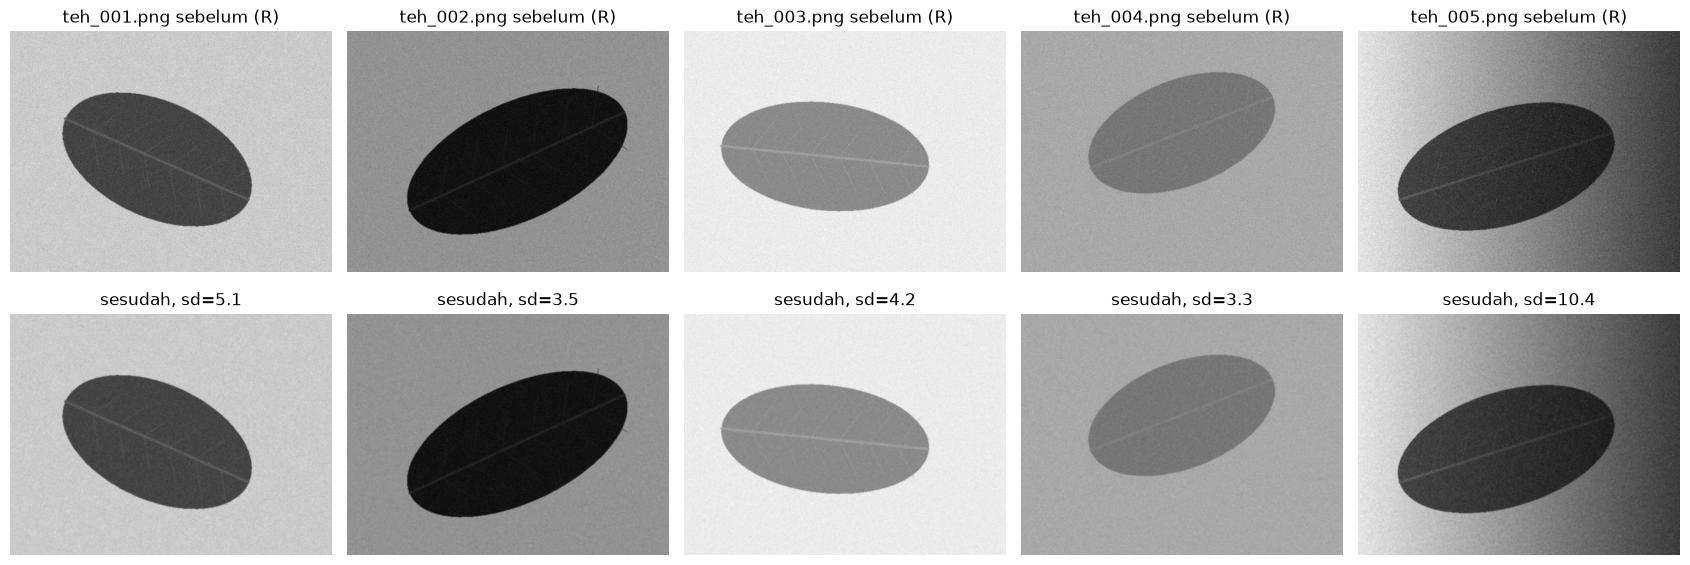

In [5]:
baris = []
for kond, nm, img, md, mb in SEHAT:
    out = praproses(img, param)
    baris.append([kond, sd_sehat(img, md), sd_sehat(out, md), bercak_palsu(img, md), bercak_palsu(out, md),
                  bercak_palsu(praproses(img, dict(param, clahe_clip=1.0)), md)])
t53 = pd.DataFrame(baris, columns=["kondisi", "sd_sebelum", "sd_sesudah", "titik_terang_sebelum", "titik_terang_sesudah", "titik_terang_bila_CLAHE"]).groupby("kondisi").mean().loc[URUT].round(2)
print(t53.to_string()); t53.to_csv("../hasil/b5_uji_sehat.csv")
print("rerata keseluruhan:", t53.mean().round(2).to_dict())
# panel sebelum dan sesudah: satu citra per kondisi (teh_001 ... teh_005)
fig, ax = plt.subplots(2, 5, figsize=(17, 6))
for j, nm in enumerate([f"teh_00{i}.png" for i in range(1, 6)]):
    img, md, mb = muat(nm); out = praproses(img, param)
    ax[0, j].imshow(img[:, :, KANAL], cmap="gray", vmin=0, vmax=255); ax[0, j].set_title(f"{nm} sebelum (R)")
    ax[1, j].imshow(out[:, :, KANAL], cmap="gray", vmin=0, vmax=255); ax[1, j].set_title(f"sesudah, sd={sd_sehat(out, md):.1f}")
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.tight_layout(); plt.savefig("../hasil/b5_panel_sehat.png", dpi=90)

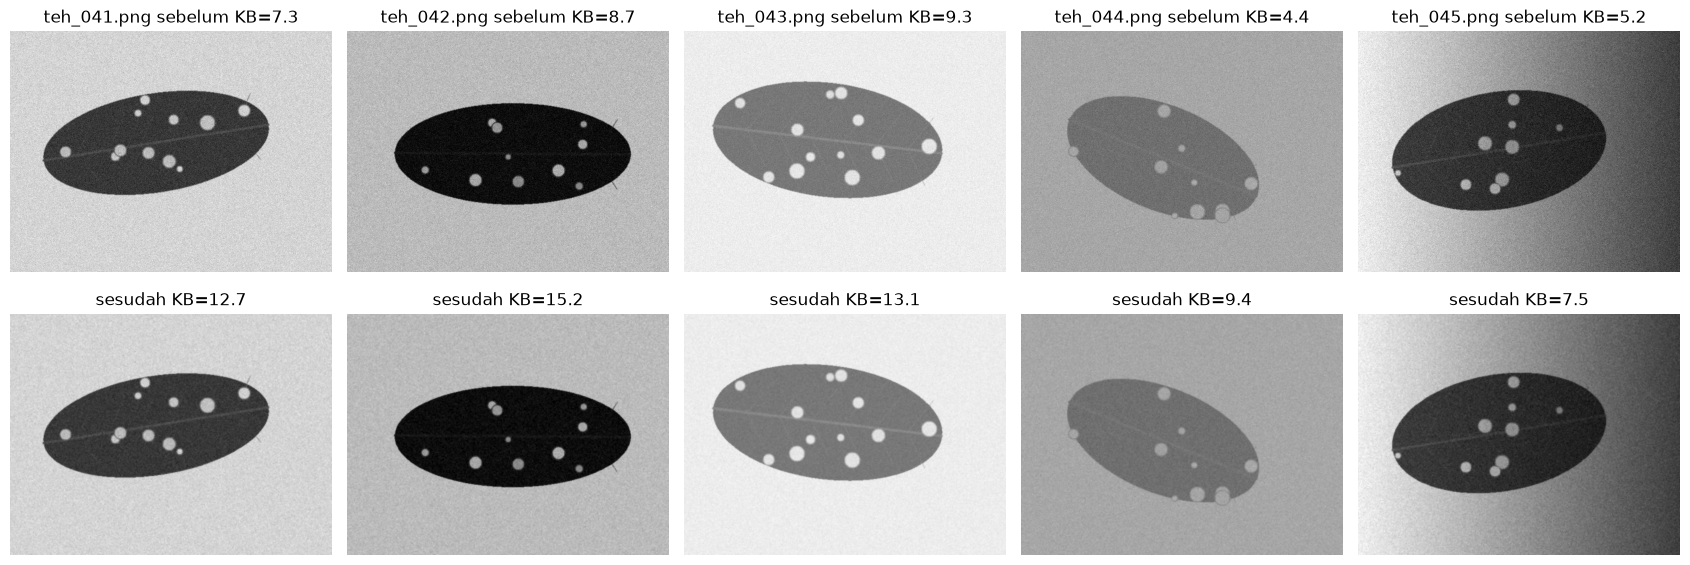

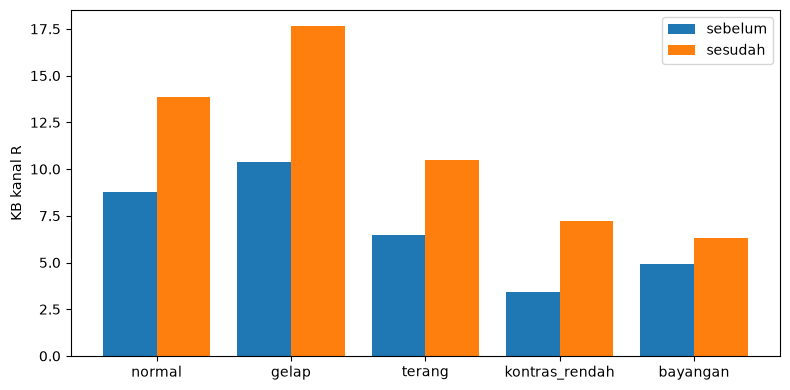

In [6]:
# panel kelas berat: satu citra per kondisi (teh_041 ... teh_045), kanal R, sebelum dan sesudah
fig, ax = plt.subplots(2, 5, figsize=(17, 6))
for j, nm in enumerate([f"teh_04{i}.png" for i in range(1, 6)]):
    img, md, mb = muat(nm); out = praproses(img, param)
    ax[0, j].imshow(img[:, :, KANAL], cmap="gray", vmin=0, vmax=255); ax[0, j].set_title(f"{nm} sebelum KB={kontras_bercak(img[:, :, KANAL], md, mb):.1f}")
    ax[1, j].imshow(out[:, :, KANAL], cmap="gray", vmin=0, vmax=255); ax[1, j].set_title(f"sesudah KB={kontras_bercak(out[:, :, KANAL], md, mb):.1f}")
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.tight_layout(); plt.savefig("../hasil/b5_panel_berat.png", dpi=90)
# grafik KB sebelum sesudah
x = np.arange(5); plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, tabel12.KB_sebelum, 0.4, label="sebelum"); plt.bar(x + 0.2, tabel12.KB_sesudah, 0.4, label="sesudah")
plt.xticks(x, URUT); plt.ylabel("KB kanal R"); plt.legend(); plt.tight_layout(); plt.savefig("../hasil/b5_kb_sebelum_sesudah.png", dpi=100)

## Langkah 5.4 Diagram rangkaian dengan parameter final

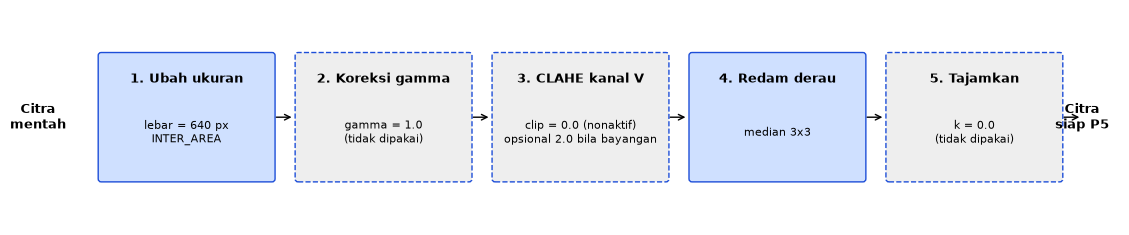

In [7]:
import matplotlib.patches as mp
p = json.load(open("../hasil/param_praproses.json"))
kot = [("1. Ubah ukuran", f"lebar = {p['lebar']} px\nINTER_AREA"),
       ("2. Koreksi gamma", f"gamma = {p['gamma']}\n(tidak dipakai)"),
       ("3. CLAHE kanal V", f"clip = {p['clahe_clip']} (nonaktif)\nopsional 2.0 bila bayangan"),
       ("4. Redam derau", f"{p['penapis']} {p['kernel']}x{p['kernel']}"),
       ("5. Tajamkan", f"k = {p['tajam_k']}\n(tidak dipakai)")]
fig, ax = plt.subplots(figsize=(14, 2.8)); ax.set_xlim(0, 14.6); ax.set_ylim(0, 2.8); ax.axis("off")
ax.text(0.05, 1.4, "Citra\nmentah", ha="center", va="center", fontsize=9, weight="bold")
for i, (j, t) in enumerate(kot):
    x = 0.9 + i * 2.65
    dash = i in (1, 2, 4)
    ax.add_patch(mp.FancyBboxPatch((x, 0.6), 2.3, 1.6, boxstyle="round,pad=0.04", fc="#eeeeee" if dash else "#cfe0ff", ec="#1d4ed8", ls="--" if dash else "-"))
    ax.text(x + 1.15, 1.85, j, ha="center", fontsize=9, weight="bold"); ax.text(x + 1.15, 1.2, t, ha="center", va="center", fontsize=8)
    ax.annotate("", xy=(x + 2.6, 1.4), xytext=(x + 2.32, 1.4), arrowprops=dict(arrowstyle="->"))
ax.text(14.1, 1.4, "Citra\nsiap P5", ha="center", va="center", fontsize=9, weight="bold")
plt.savefig("../hasil/b5_diagram_final.png", dpi=130, bbox_inches="tight")

## Uji reprodusibilitas: modul praproses dimuat dari JSON

In [8]:
from praproses import muat_param
a = praproses(baca("../data/sintetis/citra/teh_045.png"), muat_param("../hasil/param_praproses.json"))
b = praproses(baca("../data/sintetis/citra/teh_045.png"), param)
print("hasil identik dari JSON:", bool((a == b).all()), "| shape:", a.shape, "| dtype:", a.dtype)

hasil identik dari JSON: True | shape: (480, 640, 3) | dtype: uint8
